In [1]:
from medmnist import PathMNIST
from torchvision import transforms

In [2]:
transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor()
])

train = PathMNIST(split="train", transform=transform, download=False)
val   = PathMNIST(split="val",   transform=transform, download=False)
test  = PathMNIST(split="test",  transform=transform, download=False)

In [3]:
# Dataset info
print(f"Training samples: {len(train)}")
print(f"Validation samples: {len(val)}")
print(f"Test samples: {len(test)}")
print(f"Image shape: {train[0][0].shape}")
print(f"Number of classes: {len(train.info['label'])}")
print(f"Class labels: {train.info['label']}")

Training samples: 89996
Validation samples: 10004
Test samples: 7180
Image shape: torch.Size([3, 100, 100])
Number of classes: 9
Class labels: {'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models
from tqdm import tqdm

# Configuration
BATCH_SIZE = 128
NUM_EPOCHS = 20
LEARNING_RATE = 0.001

# Use MPS (Metal Performance Shaders) for faster training on macOS
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(train)

else:
    print("train is:")

    device = torch.device('cpu')

    print(f'Using device: {device}')

In [5]:
# Create data loaders
train_loader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f'Training batches: {len(train_loader)}')

# Create subset data loaders for faster training (25% of data)
from torch.utils.data import Subset
import numpy as np

x_train_indices = np.arange(0, int(len(train)/4))
x_val_indices = np.arange(0, int(len(val)/4))

x_train = Subset(train, x_train_indices)
x_val = Subset(val, x_val_indices)

x_train_loader = DataLoader(x_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
x_val_loader = DataLoader(x_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f'Reduced training batches: {len(x_train_loader)} (25% of data)')

Training batches: 704
Reduced training batches: 176 (25% of data)


In [6]:
images, labels = next(iter(train_loader))
image = images[0]
print(image.shape)

torch.Size([3, 100, 100])


In [7]:
import torch.nn as nn
import torchvision.models as models

class ResNet18Medical(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.model = models.resnet18(pretrained=True)

        self.model.fc = nn.Linear(
            self.model.fc.in_features,
            num_classes
        )

    def forward(self, x):
        return self.model(x)

In [8]:
# Initialize ResNet18Medical model
medical_model = ResNet18Medical(num_classes=len(train.info['label']))
medical_model = medical_model.to(device)
print(f'ResNet18Medical loaded with {len(train.info["label"])} output classes')

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


ResNet18Medical loaded with 9 output classes


In [9]:
# Loss function and optimizer for medical model
medical_criterion = nn.CrossEntropyLoss()
medical_optimizer = optim.Adam(medical_model.parameters(), lr=LEARNING_RATE)
medical_scheduler = optim.lr_scheduler.ReduceLROnPlateau(medical_optimizer, mode='min', patience=2, factor=0.5)

In [10]:
# Training loop for ResNet18Medical
medical_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_medical_val_acc = 0.0

for epoch in range(NUM_EPOCHS):
    print(f'\nEpoch {epoch+1}/{NUM_EPOCHS}')
    print('-' * 50)
    
    # Training phase
    medical_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    
    for images, labels in tqdm(train_loader, desc='Training'):
        images = images.to(device)
        labels = labels.squeeze().long().to(device)
        
        medical_optimizer.zero_grad()
        outputs = medical_model(images)
        loss = medical_criterion(outputs, labels)
        loss.backward()
        medical_optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = 100 * train_correct / train_total
    
    # Validation phase
    medical_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc='Validation'):
            images = images.to(device)
            labels = labels.squeeze().long().to(device)
            
            outputs = medical_model(images)
            loss = medical_criterion(outputs, labels)
            
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = 100 * val_correct / val_total
    
    # Update scheduler
    medical_scheduler.step(epoch_val_loss)
    
    # Save history
    medical_history['train_loss'].append(epoch_train_loss)
    medical_history['train_acc'].append(epoch_train_acc)
    medical_history['val_loss'].append(epoch_val_loss)
    medical_history['val_acc'].append(epoch_val_acc)
    
    print(f'Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%')
    print(f'Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%')
    
    # Save best model
    if epoch_val_acc > best_medical_val_acc:
        best_medical_val_acc = epoch_val_acc
        torch.save(medical_model.state_dict(), 'resnet18medical_pathmnist.pth')
        print(f'✓ Model saved with val acc: {best_medical_val_acc:.2f}%')

print(f'\nTraining complete! Best validation accuracy: {best_medical_val_acc:.2f}%')


Epoch 1/20
--------------------------------------------------


Validation: 100%|██████████| 79/79 [00:19<00:00,  4.00it/s]


Train Loss: 0.2316 | Train Acc: 92.13%
Val Loss: 2.0692 | Val Acc: 53.22%
✓ Model saved with val acc: 53.22%

Epoch 2/20
--------------------------------------------------


Validation: 100%|██████████| 79/79 [00:19<00:00,  3.95it/s]


Train Loss: 0.1223 | Train Acc: 95.89%
Val Loss: 1.9954 | Val Acc: 63.14%
✓ Model saved with val acc: 63.14%

Epoch 3/20
--------------------------------------------------


...

Train Loss: 0.0009 | Train Acc: 99.97%
Val Loss: 0.0495 | Val Acc: 98.88%
✓ Model saved with val acc: 98.88%

Epoch 19/20
--------------------------------------------------


Validation: 100%|██████████| 79/79 [00:18<00:00,  4.17it/s]


Train Loss: 0.0005 | Train Acc: 99.99%
Val Loss: 0.0569 | Val Acc: 98.85%

Epoch 20/20
--------------------------------------------------


Validation: 100%|██████████| 79/79 [00:20<00:00,  3.89it/s]

Train Loss: 0.0017 | Train Acc: 99.96%
Val Loss: 0.1411 | Val Acc: 97.72%

Training complete! Best validation accuracy: 98.88%


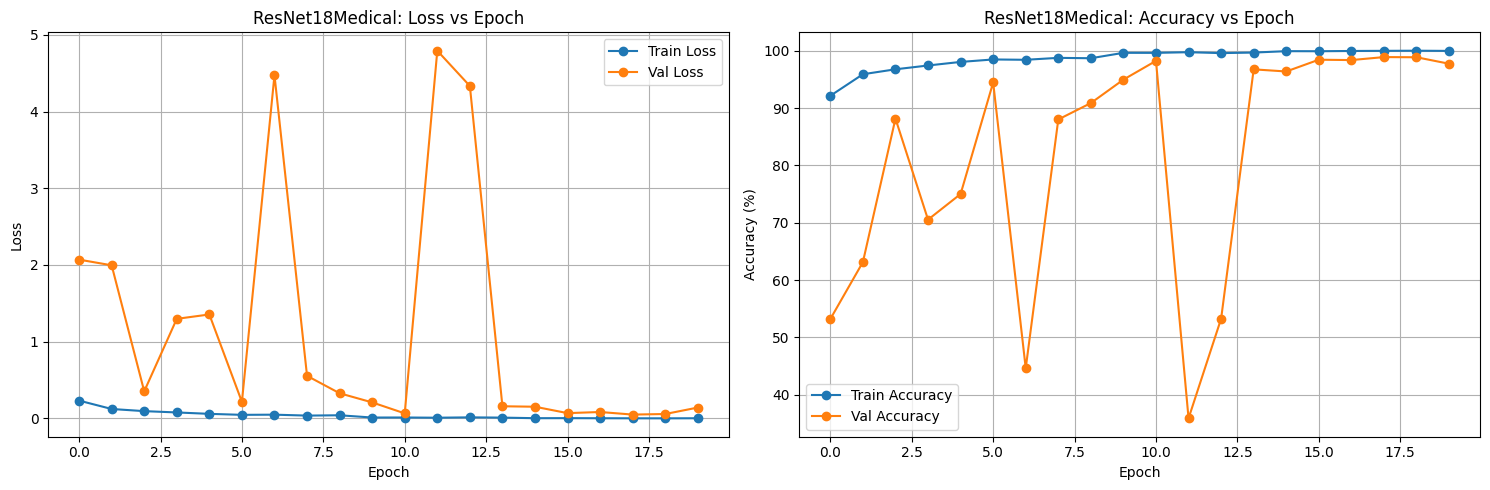

In [11]:
import matplotlib.pyplot as plt
# Plot training history for ResNet18Medical
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Loss plot
ax1.plot(medical_history['train_loss'], label='Train Loss', marker='o')
ax1.plot(medical_history['val_loss'], label='Val Loss', marker='o')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('ResNet18Medical: Loss vs Epoch')
ax1.legend()
ax1.grid(True)

# Accuracy plot
ax2.plot(medical_history['train_acc'], label='Train Accuracy', marker='o')
ax2.plot(medical_history['val_acc'], label='Val Accuracy', marker='o')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('ResNet18Medical: Accuracy vs Epoch')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [12]:
# Evaluate ResNet18Medical on test set
medical_model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='Testing ResNet18Medical'):
        images = images.to(device)
        labels = labels.squeeze().long().to(device)
        
        outputs = medical_model(images)
        _, predicted = torch.max(outputs, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_acc = 100 * test_correct / test_total
print(f'ResNet18Medical Test Accuracy: {test_acc:.2f}%')

Testing ResNet18Medical: 100%|██████████| 57/57 [00:17<00:00,  3.32it/s]

ResNet18Medical Test Accuracy: 91.80%


In [13]:
torch.save(medical_model.state_dict(), "../models/resnet18_full.pth")

# Breast Cancer Dataset Training

In [25]:
# Load Breast Cancer Dataset
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
import os

# Define transforms for breast cancer dataset
bc_transform_train = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
])

bc_transform_val = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
])

# Load full dataset
data_dir = '../data'
full_dataset = ImageFolder(root=data_dir, transform=bc_transform_train)

print(f"Total breast cancer images: {len(full_dataset)}")
print(f"Classes: {full_dataset.classes}")
print(f"Class to index mapping: {full_dataset.class_to_idx}")

Total breast cancer images: 7909
Classes: ['benign', 'malignant']
Class to index mapping: {'benign': 0, 'malignant': 1}


In [26]:
# Split dataset into train, validation, and test sets
from torch.utils.data import Subset

# Get indices for each class
indices = list(range(len(full_dataset)))
targets = [full_dataset.targets[i] for i in indices]

print(f"Total available images: {len(full_dataset)}")

# Calculate split sizes based on available data
# Target: 7000 train, 1109 val, 1000 test if enough data
total_samples = len(full_dataset)
if total_samples >= 9109:
    train_size = 7000
    val_size = 1109
    test_size = 1000
else:
    # Proportional split maintaining the ratios
    train_size = int(total_samples * 0.7684)  # 7000/9109
    val_size = int(total_samples * 0.1218)    # 1109/9109
    test_size = total_samples - train_size - val_size

print(f"Using split - Train: {train_size}, Val: {val_size}, Test: {test_size}")

# Split: First get training set
train_indices, temp_indices = train_test_split(
    indices, train_size=train_size, stratify=targets, random_state=42
)

# Then split remaining into val and test
temp_targets = [targets[i] for i in temp_indices]
remaining = len(temp_indices)
val_ratio = val_size / (val_size + test_size)
val_actual = int(remaining * val_ratio)

val_indices, test_indices = train_test_split(
    temp_indices, train_size=val_actual, stratify=temp_targets, random_state=42
)

# Create datasets with appropriate transforms
bc_train_dataset = Subset(full_dataset, train_indices)
bc_val_dataset = Subset(ImageFolder(root=data_dir, transform=bc_transform_val), val_indices)
bc_test_dataset = Subset(ImageFolder(root=data_dir, transform=bc_transform_val), test_indices)

# Create data loaders
bc_train_loader = DataLoader(bc_train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
bc_val_loader = DataLoader(bc_val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
bc_test_loader = DataLoader(bc_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Breast Cancer - Train: {len(bc_train_dataset)}, Val: {len(bc_val_dataset)}, Test: {len(bc_test_dataset)}")
print(f"Training batches: {len(bc_train_loader)}")

Total available images: 7909
Using split - Train: 6077, Val: 963, Test: 869
Breast Cancer - Train: 6077, Val: 962, Test: 870
Training batches: 48


Breast Cancer Image shape: torch.Size([3, 100, 100])
Label: Benign


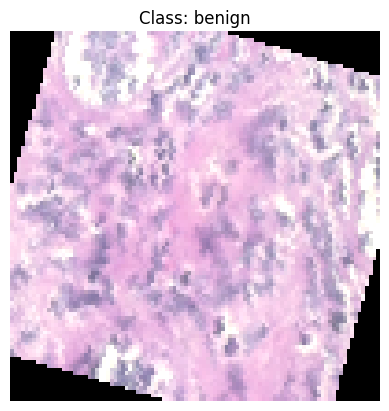

In [27]:
# Visualize a sample from breast cancer dataset
bc_images, bc_labels = next(iter(bc_train_loader))
bc_image = bc_images[0]

print(f'Breast Cancer Image shape: {bc_image.shape}')
print(f'Label: {"Malignant" if bc_labels[0].item() == 1 else "Benign"}')

import matplotlib.pyplot as plt
plt.imshow(bc_image.permute(1, 2, 0).cpu().numpy())
plt.title(f'Class: {full_dataset.classes[bc_labels[0].item()]}')
plt.axis('off')
plt.show()

In [28]:
# Initialize ResNet18 for Breast Cancer (Binary Classification)
class ResNet18BreastCancer(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.model = models.resnet18(pretrained=True)
        
        # Replace final layer for binary classification
        self.model.fc = nn.Linear(
            self.model.fc.in_features,
            num_classes
        )
    
    def forward(self, x):
        return self.model(x)

bc_model = ResNet18BreastCancer(num_classes=2)
bc_model = bc_model.to(device)
print(f'ResNet18 for Breast Cancer loaded with 2 output classes (Benign/Malignant)')

ResNet18 for Breast Cancer loaded with 2 output classes (Benign/Malignant)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [29]:
# Loss function and optimizer for breast cancer model
bc_criterion = nn.CrossEntropyLoss()
bc_optimizer = optim.Adam(bc_model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
bc_scheduler = optim.lr_scheduler.ReduceLROnPlateau(bc_optimizer, mode='min', patience=3, factor=0.5)

In [30]:
# Training loop for Breast Cancer ResNet18
bc_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_bc_val_acc = 0.0

for epoch in range(NUM_EPOCHS):
    print(f'\nEpoch {epoch+1}/{NUM_EPOCHS}')
    print('-' * 50)
    
    # Training phase
    bc_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    
    for images, labels in tqdm(bc_train_loader, desc='Training BC'):
        images = images.to(device)
        labels = labels.to(device)
        
        bc_optimizer.zero_grad()
        outputs = bc_model(images)
        loss = bc_criterion(outputs, labels)
        loss.backward()
        bc_optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = 100 * train_correct / train_total
    
    # Validation phase
    bc_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for images, labels in tqdm(bc_val_loader, desc='Validation BC'):
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = bc_model(images)
            loss = bc_criterion(outputs, labels)
            
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = 100 * val_correct / val_total
    
    # Update scheduler
    bc_scheduler.step(epoch_val_loss)
    
    # Save history
    bc_history['train_loss'].append(epoch_train_loss)
    bc_history['train_acc'].append(epoch_train_acc)
    bc_history['val_loss'].append(epoch_val_loss)
    bc_history['val_acc'].append(epoch_val_acc)
    
    print(f'Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%')
    print(f'Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%')
    
    # Save best model
    if epoch_val_acc > best_bc_val_acc:
        best_bc_val_acc = epoch_val_acc
        torch.save(bc_model.state_dict(), 'resnet18_breast_cancer.pth')
        print(f'✓ Model saved with val acc: {best_bc_val_acc:.2f}%')

print(f'\nTraining complete! Best validation accuracy: {best_bc_val_acc:.2f}%')


Epoch 1/20
--------------------------------------------------


Validation BC: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]


Train Loss: 0.4162 | Train Acc: 82.61%
Val Loss: 1.1350 | Val Acc: 46.88%
✓ Model saved with val acc: 46.88%

Epoch 2/20
--------------------------------------------------


Validation BC: 100%|██████████| 8/8 [00:14<00:00,  1.85s/it]


Train Loss: 0.2668 | Train Acc: 89.04%
Val Loss: 0.3062 | Val Acc: 86.07%
✓ Model saved with val acc: 86.07%

Epoch 3/20
--------------------------------------------------


...

Train Loss: 0.0673 | Train Acc: 97.52%
Val Loss: 0.1255 | Val Acc: 96.57%

Epoch 19/20
--------------------------------------------------


Validation BC: 100%|██████████| 8/8 [00:14<00:00,  1.87s/it]


Train Loss: 0.0657 | Train Acc: 97.63%
Val Loss: 0.1280 | Val Acc: 95.11%

Epoch 20/20
--------------------------------------------------


Validation BC: 100%|██████████| 8/8 [00:15<00:00,  1.88s/it]

Train Loss: 0.0606 | Train Acc: 97.60%
Val Loss: 0.1793 | Val Acc: 94.39%

Training complete! Best validation accuracy: 96.57%


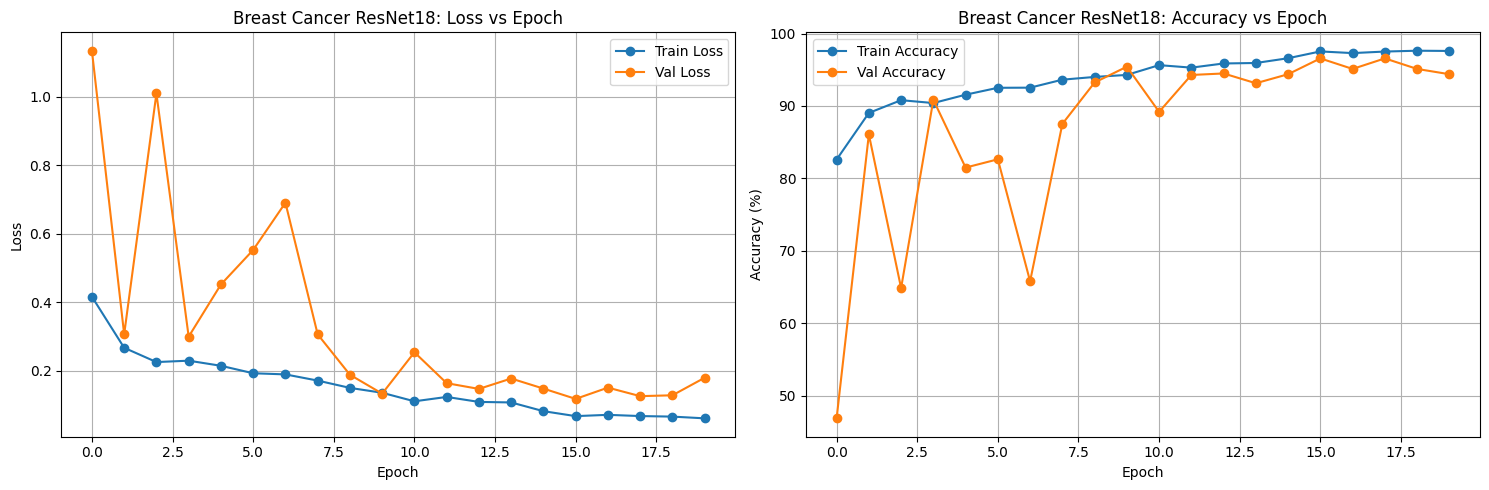

In [31]:
# Plot training history for Breast Cancer ResNet18
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Loss plot
ax1.plot(bc_history['train_loss'], label='Train Loss', marker='o')
ax1.plot(bc_history['val_loss'], label='Val Loss', marker='o')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Breast Cancer ResNet18: Loss vs Epoch')
ax1.legend()
ax1.grid(True)

# Accuracy plot
ax2.plot(bc_history['train_acc'], label='Train Accuracy', marker='o')
ax2.plot(bc_history['val_acc'], label='Val Accuracy', marker='o')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Breast Cancer ResNet18: Accuracy vs Epoch')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [32]:
# Evaluate Breast Cancer ResNet18 on test set
bc_model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in tqdm(bc_test_loader, desc='Testing BC ResNet18'):
        images = images.to(device)
        labels = labels.to(device)
        
        outputs = bc_model(images)
        _, predicted = torch.max(outputs, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

bc_test_acc = 100 * test_correct / test_total
print(f'Breast Cancer ResNet18 Test Accuracy: {bc_test_acc:.2f}%')

Testing BC ResNet18: 100%|██████████| 7/7 [00:14<00:00,  2.06s/it]

Breast Cancer ResNet18 Test Accuracy: 94.25%


In [33]:
# Save final breast cancer model
torch.save(bc_model.state_dict(), "../models/resnet18_breast_cancer_full.pth")
print("Breast cancer model saved to ../models/resnet18_breast_cancer_full.pth")

Breast cancer model saved to ../models/resnet18_breast_cancer_full.pth
